# CUSTOMER CHURN PREDICTION USING BOOSTING ALGORITHMS
### Minor Project | Student: **Bhoomika**

**Project type:** Binary classification and exploratory data analysis  
**Dataset:** IBM Telco Customer Churn (Kaggle)  
**Target:** `Churn` — whether a customer left the service.

## 1. Problem statement
Telecommunication companies lose revenue when customers stop using their services. This project analyses customer account and service information and builds machine-learning models to identify customers who may churn. The aim is to support earlier, better-focused customer-retention actions.

## 2. Objectives
- Understand the dataset and inspect its quality.
- Clean and prepare numerical and categorical features.
- Explore churn patterns using meaningful visualisations.
- Train and compare AdaBoost and Gradient Boosting with a simple baseline.
- Evaluate models using precision, recall, F1-score, ROC-AUC and a confusion matrix.
- Explain the findings, limitations and possible improvements.

## 3. Dataset source
[Kaggle – Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

The dataset contains 7,043 customer records and 21 columns (20 input attributes and the `Churn` target). Each row represents one customer. `customerID` is an identifier and is excluded from model training.

**Run note:** The notebook downloads the public CSV mirror from IBM's public GitHub repository. This is provided to make the notebook easy to run in Colab without Kaggle API credentials. If the download fails, upload `WA_Fn-UseC_-Telco-Customer-Churn.csv` from the Kaggle page and update the loading cell.

## 4. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 5. Load the dataset

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

try:
    df = pd.read_csv(DATA_URL)
except Exception:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 6. Understand the data

In [3]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\\nStatistical summary:")
display(df.describe(include="all").T)
print("\\nTarget distribution:")
display(df["Churn"].value_counts(dropna=False).to_frame("Count"))

Dataset shape: (7043, 21)
\nColumn names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
\nData types:


,Data type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


\nStatistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nTarget distribution:


,Count
Churn,
No,5174
Yes,1869


## 7. Data quality check

In [4]:
quality = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique(dropna=True),
    "Data type": df.dtypes.astype(str)
})
display(quality)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

,Missing values,Missing (%),Unique values,Data type
customerID,0,0.0,7043,object
gender,0,0.0,2,object
SeniorCitizen,0,0.0,2,int64
Partner,0,0.0,2,object
Dependents,0,0.0,2,object
tenure,0,0.0,73,int64
PhoneService,0,0.0,2,object
MultipleLines,0,0.0,3,object
InternetService,0,0.0,3,object
OnlineSecurity,0,0.0,3,object


Duplicate rows: 0
Duplicate customer IDs: 0


### Data-cleaning decisions
1. Remove exact duplicate records, if any.
2. Convert `TotalCharges` to numeric. In this dataset, blank strings represent missing values.
3. Treat `customerID` as an identifier, not a predictive feature.
4. Impute missing numerical values with the median and categorical values with the most frequent value inside a training pipeline. This avoids using test-set information during preprocessing.
5. Keep the original target classes and use a stratified train/test split so the class proportions are maintained.

In [5]:
df = df.drop_duplicates().copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Shape after duplicate removal:", df.shape)
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
print("Target values:", sorted(df["Churn"].dropna().unique()))

Shape after duplicate removal: (7043, 21)
Missing TotalCharges after conversion: 11
Target values: ['No', 'Yes']


## 8. Exploratory data analysis (EDA)

### Visualisation 1 — Churn class distribution
This chart shows how many customers stayed and how many left. Class imbalance matters because accuracy alone may hide poor detection of churners.

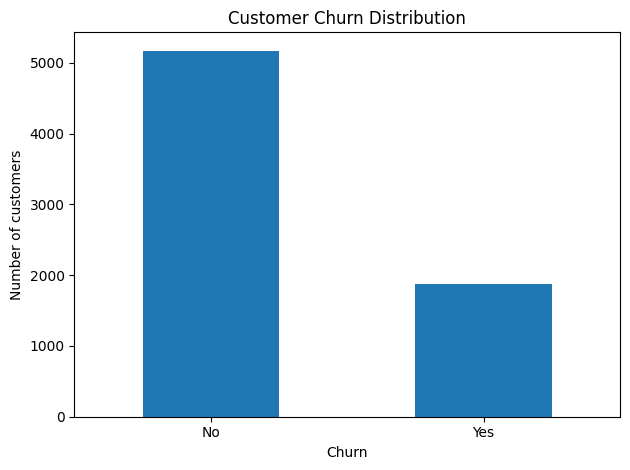

Churn percentage:


,Percentage
Churn,
No,73.46
Yes,26.54


In [6]:
target_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
target_counts.plot(kind="bar", rot=0)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Churn percentage:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

### Visualisation 2 — Churn by contract type
Compare churn proportions within each contract category, rather than only comparing raw counts.

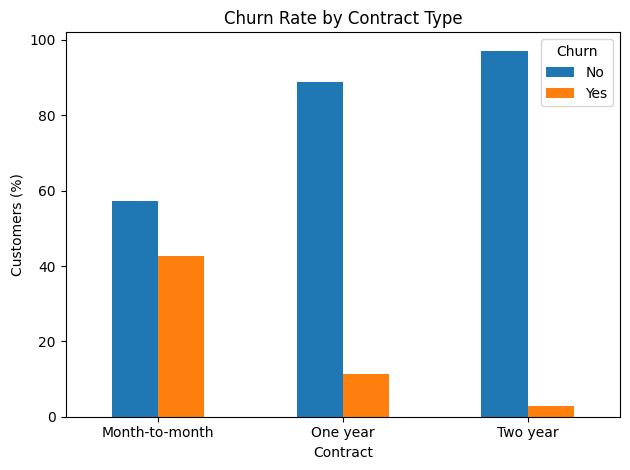

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [7]:
contract_rate = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_rate.reindex(columns=["No", "Yes"]).plot(kind="bar", rot=0)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Customers (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()
display(contract_rate.round(2))

### Visualisation 3 — Customer tenure by churn
This chart compares how long customers have stayed with the company across the two target groups.

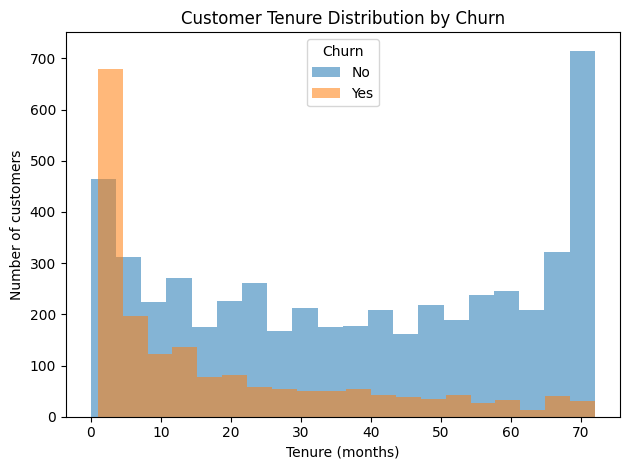

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


In [8]:
for label in ["No", "Yes"]:
    df.loc[df["Churn"] == label, "tenure"].plot(
        kind="hist", bins=20, alpha=0.55, label=label
    )
plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

display(df.groupby("Churn")["tenure"].agg(["count", "mean", "median"]).round(2))

### Visualisation 4 — Monthly charges by churn
This chart helps inspect whether monthly charges differ between customers who stayed and those who left.

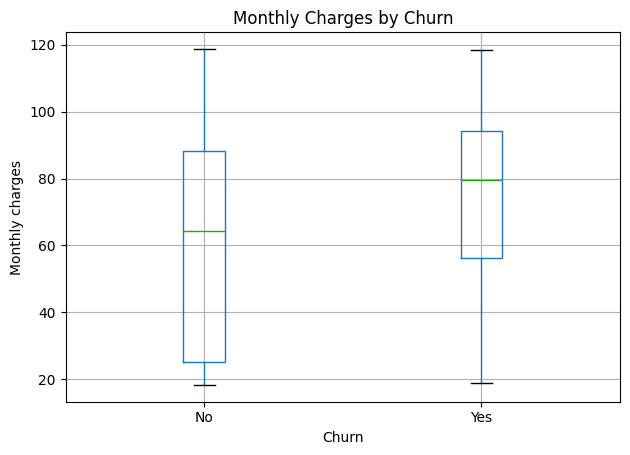

,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


In [9]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly charges")
plt.tight_layout()
plt.show()

display(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))

### Visualisation 5 — Internet service and churn
This grouped chart compares churn proportions for the available internet-service categories.

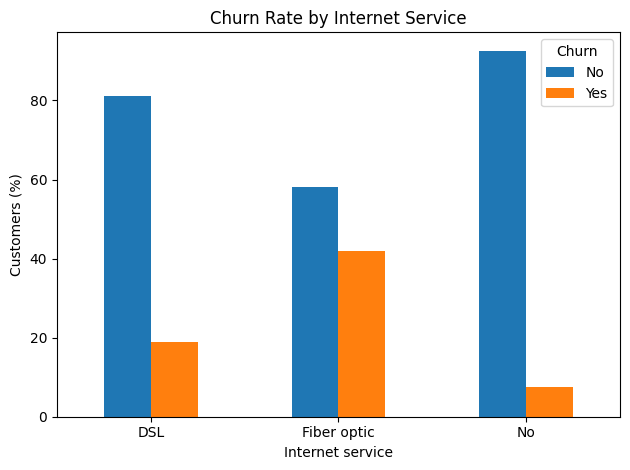

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [10]:
internet_rate = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
internet_rate.reindex(columns=["No", "Yes"]).plot(kind="bar", rot=0)
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet service")
plt.ylabel("Customers (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()
display(internet_rate.round(2))

## 9. Prepare features for modelling
The target is converted to 0/1 (`No` = 0, `Yes` = 1). The customer ID is removed. Numerical columns are median-imputed and scaled; categorical columns are mode-imputed and one-hot encoded. All transformations are fitted only on the training data through scikit-learn pipelines.

In [11]:
model_df = df.dropna(subset=["Churn"]).copy()
y = model_df["Churn"].map({"No": 0, "Yes": 1})
X = model_df.drop(columns=["Churn", "customerID"], errors="ignore")

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training records: 5634
Testing records: 1409
Numerical features: 4
Categorical features: 15


## 10. Model selection
- **AdaBoost:** combines several weak learners sequentially and gives more attention to observations that earlier learners misclassified.
- **Gradient Boosting:** builds an additive sequence of decision trees, with each stage improving the fit to the remaining errors.
- **Random Forest baseline:** an ensemble of trees trained with randomisation; included as a comparison rather than a boosting method.

The models are evaluated on the same held-out test set. The positive class is `Churn = Yes`, so recall is important when the goal is to identify as many potential churners as possible. Precision and F1-score are also reported to show the trade-off.

In [12]:
models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=150, learning_rate=0.5, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE),
    "Random Forest (baseline)": RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}

pipelines = {
    name: Pipeline([("preprocess", preprocessor), ("model", model)])
    for name, model in models.items()
}

results = []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score", ascending=False)
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest (baseline),0.7821,0.5807,0.6444,0.6109,0.8343
AdaBoost,0.7991,0.6426,0.5481,0.5916,0.8401
Gradient Boosting,0.7970,0.6538,0.5000,0.5667,0.8453


## 11. Evaluate the best model

Best model by test F1-score: Random Forest (baseline)
              precision    recall  f1-score   support

    No churn       0.87      0.83      0.85      1035
       Churn       0.58      0.64      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



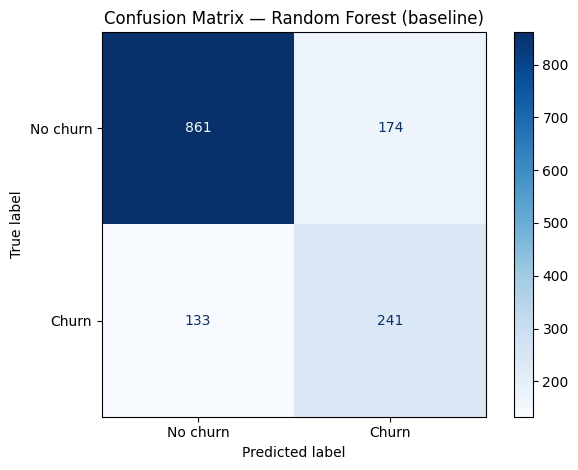

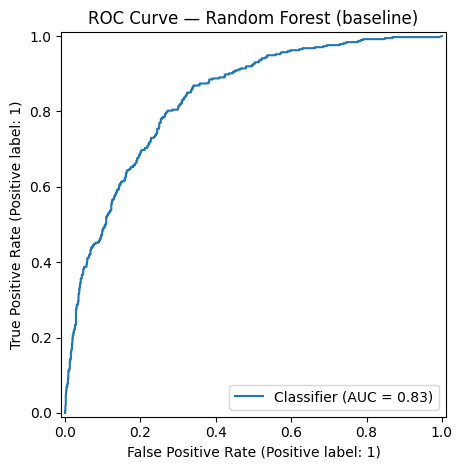

In [13]:
best_name = results_df.index[0]
best_model = pipelines[best_name]
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

print("Best model by test F1-score:", best_name)
print(classification_report(y_test, best_pred, target_names=["No churn", "Churn"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["No churn", "Churn"], cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title(f"ROC Curve — {best_name}")
plt.tight_layout()
plt.show()

## 12. Interpretation and business use
A churn prediction is a risk signal, not proof that a customer will leave. A business could use higher-risk predictions to prioritise a service check-in, review billing concerns, explain contract options or offer relevant support. Any retention action should be tested for fairness, cost and actual impact.

Use the printed EDA tables and model metrics to write the final observations after running the notebook. Do not report a metric before the notebook has produced it.

In [14]:
print(f"Selected model: {best_name}")
print("Test metrics:")
display(results_df.loc[[best_name]].round(4))

Selected model: Random Forest (baseline)
Test metrics:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest (baseline),0.7821,0.5807,0.6444,0.6109,0.8343


## 13. Conclusion
This project follows an end-to-end classification workflow: dataset understanding, data-quality checks, cleaning, exploratory visualisation, preprocessing, model training and test-set evaluation. The comparison determines whether AdaBoost or Gradient Boosting performs better than the baseline on this split.

**Complete this conclusion after running the notebook:** mention the model selected by the test F1-score, its precision/recall/ROC-AUC, two patterns visible in the EDA charts, and one limitation.

## 14. Limitations and future improvements
- The dataset is a historical sample and may not represent every telecom company or current customer behaviour.
- The target classes are not perfectly balanced; metrics beyond accuracy are necessary.
- The model identifies associations and predictive patterns, not causes of churn.
- A single train/test split gives one estimate; cross-validation and hyperparameter tuning can provide a more robust comparison.
- Future work could calibrate probabilities, tune the decision threshold based on retention costs, monitor model drift and test retention interventions.

## 15. References
1. Kaggle, **Telco Customer Churn**, BlastChar: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
2. IBM public sample-data mirror used for direct CSV loading: https://github.com/IBM/telco-customer-churn-on-icp4d
3. Scikit-learn documentation: https://scikit-learn.org/stable/

---

